# Several Target LTUs

> **Overview.** Several target LTUs (1 to 8) instead of one: does sampling the LTUs' inputs by the linear learner's
> weights still work as the number of target LTUs grows?

The step after `02_blocked_unit_distractors.ipynb`, toward the deep sparse target network, which has many target units:
the target is a sum of $K$ LTUs, each reading its own 10 of the 1,000 inputs. With one target LTU, the linear learner's
weights point at its 10 inputs, so LTUs whose inputs are sampled by those weights read mostly the target's. With $K$
target LTUs they point at all $10K$ target inputs about equally, so a sampled LTU reads only about $1/K$ of its inputs
from any one target LTU. Does sampling still let the LTUs move the network past the linear solution as $K$ grows?

**Problem.** Each sample has $N = 1000$ standard normal inputs. The target is
$\frac{1}{\sqrt{K}} \sum_{k=1}^{K} \mathrm{sign}(w_k \cdot x_k)$ plus $N(0, 0.1^2)$ noise, where target LTU $k$ reads
$x_k$, the $k$-th block of 10 inputs, with random $\pm 1$ weights $w_k$. Each sign term has zero mean and unit variance,
so the target has unit variance for every $K$; the best possible RMSE is 0.1 (dotted line), and the best linear
function of the inputs explains $2/\pi \approx 64\%$ of the target's variance, an RMSE of about 0.61 for every $K$
(dashed line: the best linear learner). Each seed has its own target weights; a run with $K$ target LTUs uses the
first $K$ of the seed's 8.

**Learner.** As in `02_blocked_unit_distractors.ipynb`: one output reading every input directly (the *linear learner*),
a bias, and 32 hidden LTUs (sigmoid derivative backward), each with a bias, every other weight starting at 0. The
hidden units' output connections carry fixed shadow weights, +1 and -1 alternately, which stand in for the real
weights in the backward pass while the real ones are smaller in magnitude. Network Autostep, online, on half the
squared error: Autostep (`squared_inputs`, initial step-size $10^{-4}$, meta step-size 0.02, $\tau = 10^4$), with the
hidden units standardized online, $h = (b - m)/\sqrt{\max(m(1 - m), 0.01)}$, the backward pass going through the
statistics. The linear learner learns alone for the first 100k steps; then the LTUs are added, and everything learns
for 1M more steps.

**Runs.** $K$ = 1, 2, 4 and 8 target LTUs, 10 seeds each; the same seed gives every run the same samples and target
weights. *LTUs reading sampled inputs*: each LTU reads 1 to 20 inputs (its fan-in uniform), drawn when the LTUs are
added, without replacement, with probability proportional to the square of the linear learner's weight on each, its
input weights starting LeCun uniform over its fan-in. *LTUs reading one target LTU's inputs* (reference): each pair of
LTUs (shadow weights +1 and -1) reads one target LTU's 10 inputs, the pairs assigned to the target LTUs in turn, so
each target LTU gets $32/K$ LTUs; their input weights start $U(-\sqrt{3/10}, \sqrt{3/10})$. *Linear learner*
(baseline): no LTUs, for each $K$. The RMSE is averaged over windows of 1k steps; final performance is the RMSE over the
last 10% of steps.

In [13]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

In [14]:
# --- Problem ---
N_INPUTS = 1000
N_SOURCES = 10                       # each target LTU reads its own block of N_SOURCES inputs, from the first
NOISE_STD = 0.1                      # observation noise on the target: the RMSE floor
LINEAR_RMSE = np.sqrt(1 - 2 / np.pi + NOISE_STD ** 2)   # the best linear learner's RMSE

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the hidden units
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
N_LTUS = 32                          # hidden LTUs
MAX_FAN_IN = 20                      # LTUs with sampled inputs read 1 to MAX_FAN_IN of them

# --- Experiment ---
LINEAR_STEPS = 100_000               # the linear learner learns alone for this many steps, then the LTUs are added
NUM_STEPS = 1_000_000                # steps after the LTUs are added
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 10
TARGET_COUNTS = (1, 2, 4, 8)         # target LTUs

## Learner

In [15]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the hidden units, each shaped (units,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each hidden unit, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the hidden units' weights over [inputs, 1 (the bias)], of which they read those in `reads`;
    # w['output'] is the output's weights over [inputs (the linear learner), the hidden units, 1]. `mask` says which of
    # the output's connections exist; the hidden units' are switched on when the units are added.
    w: dict                     # {'hidden': (slots, N_INPUTS + 1), 'output': (1, N_INPUTS + slots + 1)}
    reads: jax.Array            # (slots, N_INPUTS + 1)
    mask: jax.Array             # shaped like w['output']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (slots,): each hidden unit's shadow output weight, +-1, or 0 for an empty slot


def init_net(key, units, slots, targets):
    # `units` hidden units in `slots` slots, the rest left empty, each pair reading the inputs of one of the `targets`
    # target LTUs in turn and the bias; their shadow weights +1 and -1 alternately, their input weights LeCun uniform,
    # U(-sqrt(3 / N_SOURCES), sqrt(3 / N_SOURCES)); every other weight at 0.
    target = jnp.arange(slots) // 2 % targets
    reads = jnp.append(jnp.arange(N_INPUTS) // N_SOURCES == target[:, None], jnp.ones((slots, 1), bool), axis=1)
    shadow = jnp.where(jnp.arange(slots) < units, jnp.where(jnp.arange(slots) % 2 == 0, 1.0, -1.0), 0.0)
    mask = jnp.concatenate([jnp.ones(N_INPUTS, bool), jnp.zeros(slots, bool), jnp.ones(1, bool)])[None]
    w = {'hidden': (jax.random.uniform(key, (slots, N_INPUTS + 1), minval=-1.0, maxval=1.0)
                    * jnp.sqrt(3.0 / N_SOURCES) * reads).at[:, -1].set(0.0),
         'output': jnp.zeros((1, N_INPUTS + slots + 1))}
    stats = Stats(jnp.full(slots, 0.5), jnp.zeros(slots), jnp.zeros(slots))
    return Net(w, reads, mask, OPTIMIZER.init(w), stats, shadow)


def wire_by_readout(net, key):
    # Each hidden unit reads 1 to MAX_FAN_IN inputs (uniform) and the bias, the inputs drawn without replacement with
    # probability proportional to the square of the linear learner's weight on them (Gumbel top-k), with fresh LeCun
    # uniform input weights over its fan-in and fresh statistics.
    slots = len(net.shadow)
    fan_key, draw_key, w_key = jax.random.split(key, 3)
    fan_in = jax.random.randint(fan_key, (slots, 1), 1, MAX_FAN_IN + 1)
    scores = jnp.log(net.w['output'][0, :N_INPUTS] ** 2) + jax.random.gumbel(draw_key, (slots, N_INPUTS))
    reads = jnp.append(jnp.argsort(jnp.argsort(-scores)) < fan_in, jnp.ones((slots, 1), bool), axis=1)
    hidden = jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / fan_in) * reads
    stats = Stats(jnp.full(slots, 0.5), jnp.zeros(slots), jnp.zeros(slots))
    return net._replace(w={**net.w, 'hidden': hidden.at[:, -1].set(0.0)}, reads=reads, stats=stats)


def learn(net, x, y):
    # One online network-Autostep update on half the squared error, each shadow weight standing in for its hidden
    # unit's output weight in the backward pass while the real one is smaller in magnitude. Returns the new network and
    # the squared error on this sample, before learning from it. `probe` is zero; its gradient is the error arriving at
    # each hidden unit.
    units = len(net.shadow)

    def loss_fn(w, probe):
        w = {'hidden': w['hidden'] * net.reads, 'output': w['output'] * net.mask}
        b = ltu(w['hidden'] @ jnp.append(x, 1.0))
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        h = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean)
        a = h + probe
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][0, N_INPUTS:N_INPUTS + units]
        through_back = jnp.sum(jnp.where(jnp.abs(unit_w) < 1.0, net.shadow, unit_w) * net.mask[0, N_INPUTS:-1] * a)
        prediction = (w['output'] @ jax.lax.stop_gradient(source) + through_back
                      - jax.lax.stop_gradient(through_back))
        sources = {'hidden': jnp.append(x, 1.0) * net.reads,
                   'output': jax.lax.stop_gradient(source)[None] * net.mask}
        return 0.5 * jnp.sum((prediction - y) ** 2), (sources, jax.lax.stop_gradient(h), mean)

    (loss, (sources, h, mean)), (grads, error) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(net.w, jnp.zeros(units))
    grads = {'hidden': grads['hidden'] * net.reads, 'output': grads['output'] * net.mask}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats), 2 * loss

## Training

In [16]:
def train(net, key, targets, sampled, add_step, num_steps):
    # num_steps online network-Autostep steps on targets from this seed's first `targets` target LTUs, the hidden units
    # added at add_step (first rewired by wire_by_readout if sampled). Returns each window's mean squared error.
    target_key, key = jax.random.split(key)
    wire_key = jax.random.fold_in(target_key, 1)
    target_w = jax.random.rademacher(target_key, (max(TARGET_COUNTS), N_SOURCES), dtype=float)
    used = jnp.arange(max(TARGET_COUNTS)) < targets

    def one_step(net, inputs):
        step, key = inputs
        x_key, noise_key = jax.random.split(key)
        x = jax.random.normal(x_key, (N_INPUTS,))
        blocks = x[:target_w.size].reshape(target_w.shape)
        y = (jnp.sum(jnp.where(jnp.sum(target_w * blocks, 1) > 0, 1.0, -1.0) * used) / jnp.sqrt(targets)
             + NOISE_STD * jax.random.normal(noise_key, (1,)))
        net = net._replace(mask=net.mask.at[0, N_INPUTS:-1].set((step >= add_step) & (net.shadow != 0)))
        return learn(net, x, y)

    def window(net, inputs):
        index, key = inputs
        net, mse = jax.lax.scan(one_step, net, (index * WINDOW + jnp.arange(WINDOW), jax.random.split(key, WINDOW)))
        return net, mse.mean()

    n, added = num_steps // WINDOW, add_step // WINDOW
    index, keys = jnp.arange(n), jax.random.split(key, n)
    net, before = jax.lax.scan(window, net, (index[:added], keys[:added]))
    net = jax.tree.map(lambda a, b: jnp.where(sampled, a, b), wire_by_readout(net, wire_key), net)
    return jnp.concatenate([before, jax.lax.scan(window, net, (index[added:], keys[added:]))[1]])


def run(configs):
    # Each (units, targets, sampled) of configs: `units` hidden LTUs reading sampled inputs if sampled, and one target
    # LTU's inputs otherwise (no LTUs: the linear learner alone), on `targets` target LTUs, each on N_SEEDS seeds,
    # vmapped together. Seed s gives every run the same samples and target weights. Returns {config: the RMSE of each
    # window from step 1, shaped (seed, window)}.
    units, targets, sampled, seed = (jnp.array(v) for v in zip(*[(*c, s) for c in configs for s in range(N_SEEDS)]))
    slots = max(max(u for u, _, _ in configs), 1)
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    nets = jax.vmap(lambda k, u, t: init_net(k, u, slots, t))(keys(0), units, targets)
    train_all = jax.jit(jax.vmap(lambda n, k, t, s: train(n, k, t, s, LINEAR_STEPS, LINEAR_STEPS + NUM_STEPS)))
    mse = train_all(nets, keys(1), targets, sampled)
    return dict(zip(configs, np.sqrt(np.asarray(mse)).reshape(len(configs), N_SEEDS, -1)))

## Runs

In [17]:
started = perf_counter()
linear = run([(0, k, False) for k in TARGET_COUNTS])
ltus = run([(N_LTUS, k, s) for k in TARGET_COUNTS for s in (True, False)])
print(f'{(len(linear) + len(ltus)) * N_SEEDS} runs in {perf_counter() - started:.0f}s')
linear = {k: linear[(0, k, False)] for k in TARGET_COUNTS}
sampled = {k: ltus[(N_LTUS, k, True)] for k in TARGET_COUNTS}
reference = {k: ltus[(N_LTUS, k, False)] for k in TARGET_COUNTS}

120 runs in 121s


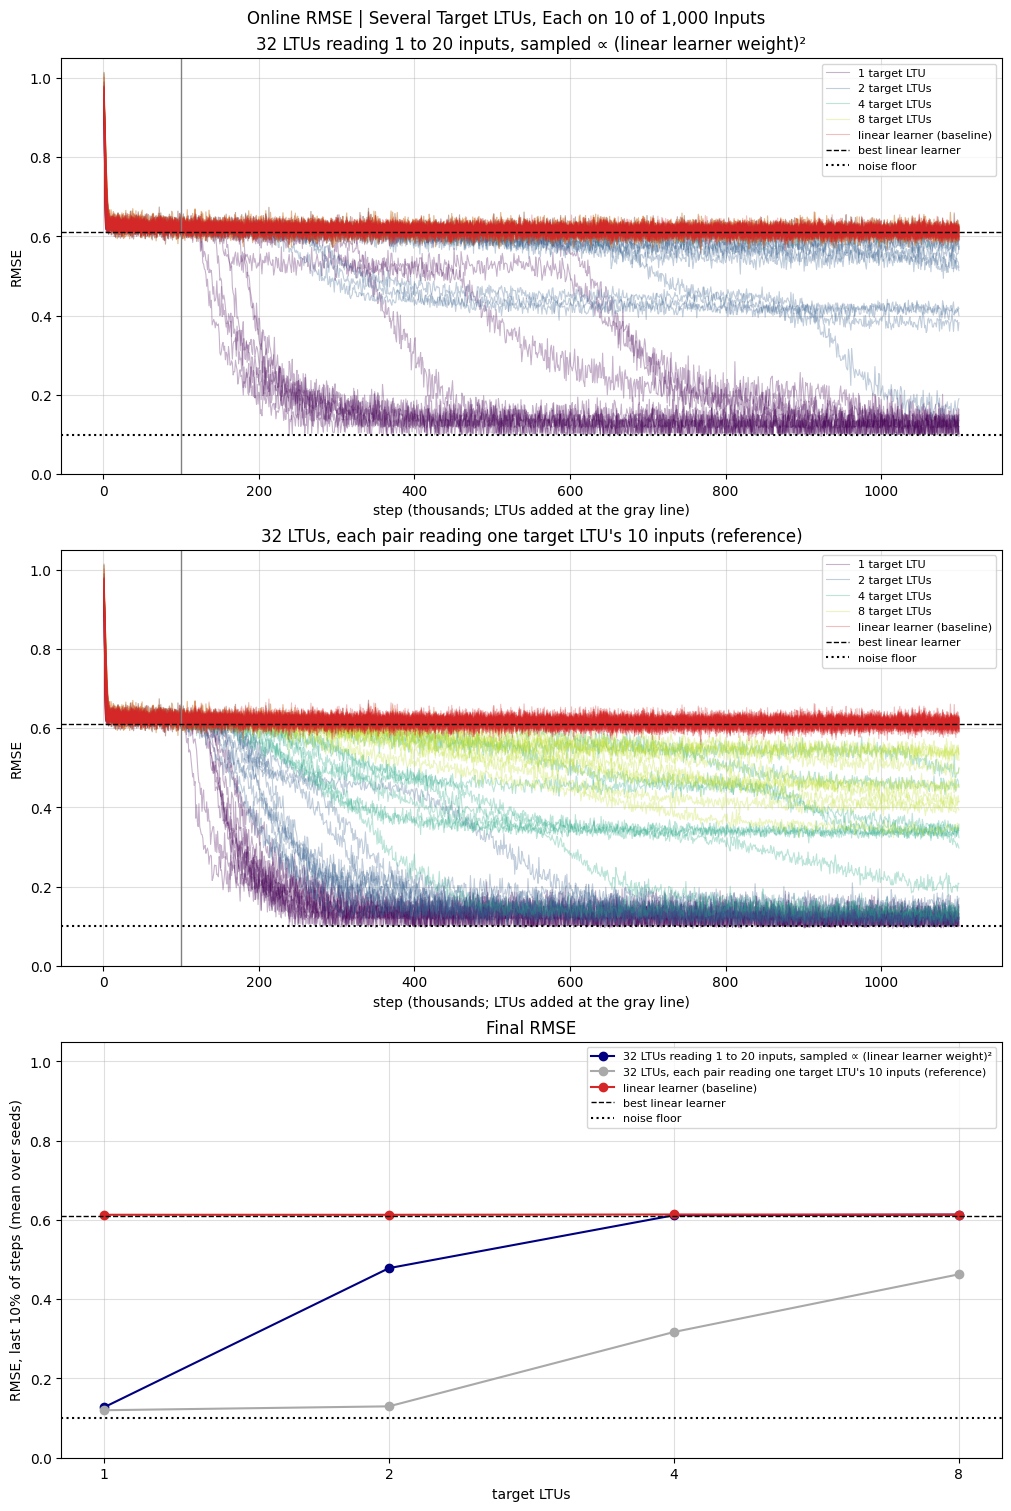

In [18]:
STEPS = (np.arange((LINEAR_STEPS + NUM_STEPS) // WINDOW) + 1) * WINDOW
TARGET_COLORS = dict(zip(TARGET_COUNTS, plt.cm.viridis(np.linspace(0, 0.9, len(TARGET_COUNTS)))))
PANELS = {f'{N_LTUS} LTUs reading 1 to {MAX_FAN_IN} inputs, sampled ∝ (linear learner weight)²': sampled,
          f"{N_LTUS} LTUs, each pair reading one target LTU's 10 inputs (reference)": reference}
final = lambda rmse: rmse[:, -(NUM_STEPS // WINDOW // 10):].mean(1)   # each seed's RMSE over the last 10% of steps

fig, axes = plt.subplots(3, 1, figsize=(10, 15), layout='constrained')
for ax, (title, runs) in zip(axes, PANELS.items()):
    for targets, seeds in runs.items():
        for i, seed in enumerate(seeds):
            ax.plot(STEPS / 1000, seed, color=TARGET_COLORS[targets], lw=0.8, alpha=0.3,
                    label=None if i else f'{targets} target LTU{"s" if targets > 1 else ""}')
    for i, seed in enumerate(np.concatenate(list(linear.values()))):
        ax.plot(STEPS / 1000, seed, color='tab:red', lw=0.8, alpha=0.3, label=None if i else 'linear learner (baseline)')
    ax.axvline(LINEAR_STEPS / 1000, color='gray', lw=1)
    ax.set(xlabel='step (thousands; LTUs added at the gray line)', ylabel='RMSE', ylim=(0, 1.05), title=title)

ax = axes[2]
for (title, runs), color in zip({**PANELS, 'linear learner (baseline)': linear}.items(), ['navy', 'darkgray', 'tab:red']):
    ax.plot(TARGET_COUNTS, [final(seeds).mean() for seeds in runs.values()], 'o-', color=color, label=title)
ax.set_xscale('log', base=2)
ax.set_xticks(TARGET_COUNTS, [str(n) for n in TARGET_COUNTS])
ax.set(xlabel='target LTUs', ylabel='RMSE, last 10% of steps (mean over seeds)', ylim=(0, 1.05), title='Final RMSE')
for ax in axes:
    ax.axhline(LINEAR_RMSE, color='black', ls='--', lw=1, label='best linear learner')
    ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
    ax.grid(alpha=0.4)
    ax.legend(fontsize=8)
fig.suptitle('Online RMSE | Several Target LTUs, Each on 10 of 1,000 Inputs')
plt.show()

## Results

10 seeds per configuration; final performance is the RMSE over the last 10% of steps. The notebook takes about 2
minutes.

- **Sampling inputs by the linear learner's weights stops working as the number of target LTUs grows**: the final RMSE
  is 0.13 with 1 target LTU (every run ends below 0.3), 0.48 with 2 (1 run of 10), and 0.61 with 4 and 8 (none), the
  same as the linear learner alone.
- **The reference degrades more slowly**: 0.12, 0.13, 0.32 and 0.46 (10, 10, 3 and 0 runs below 0.3). It slows down
  too, probably because each target LTU carries only $1/K$ of the target's variance and gets only $32/K$ LTUs.
- The linear learner reaches about 0.62 within 10k steps for every $K$, so the LTUs are always added to a converged
  linear solution.